# ChessGPT — v3: LSTM, a recurrent memory of the whole game

## Where we are
| Version | Model | Context | Bits/char | Legal move rate | Self-play plies |
|---|---|---|---|---|---|
| — | Frequency baseline | none | — | 11.2% | — |
| v1 | Bigram | 1 char | 2.430 | 10.2% | 0.36 |
| v2 | MLP + embeddings | 16 chars | 1.558 | 36.5% | 6.91 |

The v2 MLP was **78% legal in the opening**, but only about **21–26% in the middle game**: pieces moved more than ~4 moves earlier fall outside its 16-character window.

## The idea of v3
A **recurrent neural network** reads the game **one character at a time, from the very first move**, and updates a **hidden state**: a vector that acts as its memory of everything read so far.
In principle the hidden state can keep track of where every piece is, however long the game.

We use an **LSTM** (Long Short-Term Memory, Hochreiter & Schmidhuber, 1997), the recurrent architecture designed to keep information for a long time.

## What is new in v3
- **Recurrent networks**: hidden state, unrolling through time, backpropagation through time.
- **LSTM gates**: forget, input and output gates, and the cell state.
- **Truncated backpropagation through time** on a stream of games, and whole-game validation with padding and a **masked** loss.
- **Gradient clipping** against exploding gradients.
- **Incremental sampling**: the hidden state is carried forward, so each new character costs one step instead of re-reading the whole game.
- A new diagnostic: **loss as a function of the position in the game**. Does the memory hold up in long games?

## Requirements and time
Run `chessgpt_v1.ipynb` first (cleaned games). Training is heavier than v2: the training cell prints the measured time per step after 20 steps, with a projection of the total. To make it faster, reduce `EPOCHS` in Step 4.

In [1]:
# --- CORE LIBRARIES ---

# PyTorch: tensors, automatic gradients, neural networks.
import torch

# Neural network layers (Embedding, LSTM, Linear).
import torch.nn as nn

# Functional operations: softmax, cross-entropy.
import torch.nn.functional as F

# Numerical computing.
import numpy as np

# Plotting.
import matplotlib.pyplot as plt

# python-chess: rules, legal moves, SAN parsing.
import chess

# SVG drawings of chess boards.
import chess.svg

# Display SVG images in the notebook.
from IPython.display import SVG, display

# Counting occurrences.
from collections import Counter

# File and folder paths.
from pathlib import Path

# Regular expressions (SAN grammar).
import re

# Measure execution time.
import time

# Python's random module.
import random

# Shared results file.
import json

# Independent copies of objects (CPU copy of the model).
import copy

In [2]:
# --- DEVICE AND REPRODUCIBILITY ---

# Fastest device available: NVIDIA GPU, Apple Silicon GPU, or CPU.
if torch.cuda.is_available():

    # NVIDIA GPU.
    device = torch.device("cuda")

elif torch.backends.mps.is_available():

    # Apple Silicon GPU.
    device = torch.device("mps")

else:

    # CPU (slow for this model).
    device = torch.device("cpu")

# Seed for PyTorch.
torch.manual_seed(42)

# Seed for Python's random module.
random.seed(42)

# Seed for NumPy.
np.random.seed(42)

# Print the device.
print("Device:", device)

Device: mps


## Step 1 — Same data, vocabulary and split as v1 and v2

Identical to v2: the games cleaned by v1, the same 29-character vocabulary, the same split (seed 42), and later the same 1,000 test positions (seed 123).

In [3]:
# --- LOAD THE CLEANED GAMES FROM v1 ---

# Folder with the chess data.
DATA_DIR = Path("data/lichess")

# File written by v1.
GAMES_PATH = DATA_DIR / "games_2013-01.txt"

# Stop if v1 has not been run.
assert GAMES_PATH.exists(), "Run chessgpt_v1.ipynb first."

# One game per line.
games = GAMES_PATH.read_text(encoding="utf-8").split("\n")

# --- SAME VOCABULARY ---

# Start/end-of-game token.
SEP = ";"

# Same sorted characters.
chars = sorted(set("".join(games)) | {SEP})

# Vocabulary size (29).
V = len(chars)

# Character -> index.
stoi = {c: i for i, c in enumerate(chars)}

# Index -> character.
itos = {i: c for c, i in stoi.items()}

# --- SAME SPLIT ---

# Copy of the games.
shuffled = games[:]

# Same shuffle (seed 42).
random.Random(42).shuffle(shuffled)

# 5% validation, 5% test.
n_val = n_test = len(shuffled) // 20

# Validation games.
val_games = shuffled[:n_val]

# Test games.
test_games = shuffled[n_val:n_val + n_test]

# Training games.
train_games = shuffled[n_val + n_test:]

# Checks.
print(f"Vocabulary: {V} | Train: {len(train_games):,} | Validation: {len(val_games):,} | Test: {len(test_games):,}")

# --- FAST ENCODING ---

# Byte value -> vocabulary index.
lookup = np.full(256, -1, dtype=np.int64)

# Fill the table.
for c, i in stoi.items():

    # One entry per character.
    lookup[ord(c)] = i


# Encode a string into vocabulary indices.
def encode(text):
    """String -> int64 NumPy array of vocabulary indices."""

    # Raw bytes through the lookup table.
    ids = lookup[np.frombuffer(text.encode("ascii"), dtype=np.uint8)]

    # Safety check.
    assert (ids >= 0).all()

    # Return the indices.
    return ids

Vocabulary: 29 | Train: 104,066 | Validation: 5,781 | Test: 5,781


## Step 2 — Feeding the LSTM: a stream for training, whole games for validation

### Why not train on whole games?
The first version of this notebook trained on batches of 64 whole games, backpropagating through all ~640 characters of each game. On the Apple GPU it measured **21 seconds per step**, about 17 hours of training. There were two reasons. The first was an inefficiency in the backward pass, fixed in Step 3 (`unbind`). The second is fundamental: every update had to run 640 *sequential* LSTM steps forward and as many backward, each one a separate small GPU operation, and a GPU cannot parallelise along time. The bottleneck is the **number of sequential steps per update**.

### Truncated backpropagation through time (TBPTT)
The classic solution, used for example by Karpathy's char-rnn:

1. Join all training games into one long text, separated by `;` (the same text as v1 and v2): `;g1;g2;g3;…;`
2. Cut it into $B = 512$ rows of equal length: 512 independent **streams**, read in parallel.
3. Read the streams in consecutive **chunks** of $T = 64$ characters. One optimisation step processes one chunk of all 512 streams: inputs of shape $(512, 64)$, targets shifted by one character.
4. The state at the end of chunk $k$ becomes the initial state of chunk $k+1$, so the **memory flows forward without limit**. The **gradient**, however, stops at the chunk boundary: we **detach** the state from the computation graph.

$$
(h_0, c_0)^{(k+1)} = \operatorname{detach}\big((h_T, c_T)^{(k)}\big),
\qquad
\nabla_\theta L^{(k)} \text{ flows back through the } T \text{ steps of chunk } k \text{ only}
$$

The trade-off: the model can **use** information from arbitrarily far back (the state carries it), but the gradient that **teaches** it to store information spans at most $T = 64$ characters, about 15 plies. In practice LSTMs still learn to keep information much longer than $T$: what is useful to remember within a window keeps being useful beyond it.

The gain: an update needs 64 sequential steps instead of 640, and processes $512 \times 64 = 32{,}768$ characters at once.

### Games inside the stream
In the stream, a game starts right after the `;` of the previous one, while the state still remembers the previous game. The LSTM must learn that `;` means "new game: forget the old position", a natural job for the forget gate.
There is no padding and no cut: every character of every training game is a real target, long games included.

### Validation: whole games, padding and masking
For the validation loss we evaluate every game **separately, from a zero state**, exactly as the sampler will use the model. Input `;e4 e5 Nf3 …`, targets shifted by one, `e4 e5 Nf3 … ;`:

```
input :  ;  e  4  ␣  e  5  ␣  N  f  3 ...
target:  e  4  ␣  e  5  ␣  N  f  3  ␣ ...
```

These are exactly the targets of v1 and v2 (every character of the game plus the final `;`), so bits per character remain comparable.

Games have different lengths, but a batch must be a rectangle. Shorter games are **padded** at the end, and the padded positions are **masked** out of the loss: their target is set to `-100`, the value `F.cross_entropy` ignores (`ignore_index`).

$$
L = \frac{1}{\sum_{b,t} m_{b,t}} \sum_{b,t} m_{b,t}\; \ell\big(z_{b,t}, y_{b,t}\big),
\qquad
m_{b,t} = \begin{cases} 1 & \text{real character} \\ 0 & \text{padding} \end{cases}
$$

The LSTM reads from left to right, so padding placed *after* the end of a game never affects the predictions *inside* it.
The validation games are stored in one byte matrix (`uint8`), one row per game. Each batch is trimmed to its longest game.

### Where the data lives
The training grid and the validation matrix stay in the **CPU** memory; only the batch being used (a few hundred KB) is copied to the GPU. On Apple GPUs, slicing columns out of a large `uint8` tensor stored on the GPU returned **all zeros** (a bug of the `mps` backend): the model would silently train on garbage. Keeping the data on the CPU avoids it, and the `assert` after the example checks that the first batch really contains the first game. Lesson: **always look at your batches** before training.

In [4]:
# --- TRAINING STREAM FOR TRUNCATED BPTT ---

# Number of parallel streams (rows of every training batch).
N_STREAMS = 512

# Truncation length: characters per chunk, i.e. steps of backpropagation through time.
BPTT = 64

# All training games in one text: ';' + games separated by ';' + ';' (the same text as v1 and v2).
train_stream = encode(SEP + SEP.join(train_games) + SEP)

# Length of each stream (the few characters that do not fill a complete row are dropped).
n_cols = len(train_stream) // N_STREAMS

# Cut the text into N_STREAMS contiguous rows. The grid stays on the CPU (about 30 MB as uint8): only each small chunk is sent to the GPU.
train_grid = torch.from_numpy(train_stream[:N_STREAMS * n_cols].reshape(N_STREAMS, n_cols).astype(np.uint8))

# Complete chunks in one pass over the data (the last target needs one extra column).
chunks_per_epoch = (n_cols - 1) // BPTT

# Summary.
print(f"Training stream: {len(train_stream):,} characters -> grid {tuple(train_grid.shape)} | "
      f"{chunks_per_epoch:,} chunks of {N_STREAMS} x {BPTT} per epoch")


# Inputs and targets of chunk number k.
def get_chunk(k):
    """Return inputs and targets of shape (N_STREAMS, BPTT); targets are the inputs shifted by one character."""

    # First column of the chunk.
    start = k * BPTT

    # Inputs: BPTT consecutive characters of every stream, converted to int64 on the CPU, then sent to the device.
    x = train_grid[:, start:start + BPTT].long().to(device)

    # Targets: the next character at every position.
    y = train_grid[:, start + 1:start + BPTT + 1].long().to(device)

    # Return both.
    return x, y


# Example: the first chunk.
x_ex, y_ex = get_chunk(0)

# First 30 inputs of the first stream.
print("input :", "".join(itos[i] for i in x_ex[0, :30].tolist()))

# The corresponding targets.
print("target:", "".join(itos[i] for i in y_ex[0, :30].tolist()))

# Sanity check: the stream must start with ';' followed by the first training game.
assert "".join(itos[i] for i in x_ex[0, :30].tolist()) == (SEP + train_games[0])[:30], "the batch does not match the data"

# --- VALIDATION: WHOLE GAMES IN A PADDED MATRIX ---

# Padding value in the byte matrix (not a vocabulary index).
PAD = 255


# Build a padded byte matrix with one row per game: ';' + game + ';'.
def build_matrix(game_list):
    """Return (uint8 matrix N x L, lengths N) where lengths count the valid tokens of each row."""

    # Encoded rows: start token + game + end token.
    rows = [encode(SEP + g + SEP).astype(np.uint8) for g in game_list]

    # Number of valid tokens of each row.
    lengths = np.array([len(r) for r in rows])

    # Matrix filled with the padding value, as wide as the longest row.
    matrix = np.full((len(rows), lengths.max()), PAD, dtype=np.uint8)

    # Copy each row to the left of its line.
    for i, r in enumerate(rows):

        # Valid tokens first, padding after.
        matrix[i, :len(r)] = r

    # Return both.
    return matrix, lengths


# Validation matrix (full games).
val_matrix, val_lengths = build_matrix(val_games)

# Shape and size.
print(f"Validation matrix: {val_matrix.shape}, {val_matrix.nbytes / 1024**2:.0f} MB")

# Validation data, kept on the CPU (each batch is sent to the device when needed).
val_matrix_t = torch.from_numpy(val_matrix)

# Validation lengths, on the CPU too.
val_lengths_t = torch.from_numpy(val_lengths)


# Turn selected rows of a byte matrix into (inputs, targets) for the LSTM.
def make_batch(matrix_t, lengths_t, rows):
    """rows: tensor of row indices. Returns inputs (B, L-1) and targets (B, L-1) with -100 on padding."""

    # Length of the longest selected game: columns beyond it are padding for every row, so we drop them.
    L = int(lengths_t[rows].max())

    # Selected rows, as int64 indices (built on the CPU, where the matrix lives).
    seq = matrix_t[rows, :L].long()

    # Inputs: all tokens but the last; padding replaced by ';' (any valid index works, it is masked anyway).
    inputs = seq[:, :-1].masked_fill(seq[:, :-1] == PAD, stoi[SEP])

    # Targets: all tokens but the first; padding replaced by -100 so the loss ignores it.
    targets = seq[:, 1:].masked_fill(seq[:, 1:] == PAD, -100)

    # Send both to the device.
    return inputs.to(device), targets.to(device)

Training stream: 30,128,102 characters -> grid (512, 58843) | 919 chunks of 512 x 64 per epoch
input : ;d4 d5 e4 dxe4 Nc3 Bf5 g4 Bg6 
target: d4 d5 e4 dxe4 Nc3 Bf5 g4 Bg6 N
Validation matrix: (5781, 1052), 6 MB


## Step 3 — The model: embedding + 2-layer LSTM + output layer

### From an RNN to an LSTM
A plain RNN updates its hidden state with the current input:

$$
h_t = \tanh(W_x x_t + W_h h_{t-1} + b)
$$

During backpropagation the gradient flowing from step $t$ back to step $t - k$ is multiplied $k$ times by $W_h$ (and by the derivative of tanh). Over hundreds of characters it **vanishes** or **explodes**, so a plain RNN struggles to remember anything for long. This is the same problem we met with deep networks in the animal project.

The **LSTM** adds a second state, the **cell state** $c_t$, controlled by three **gates** with values between 0 and 1:

$$
\begin{aligned}
f_t &= \sigma(W_f [h_{t-1}, x_t] + b_f) && \text{forget gate: how much of the old memory to keep} \\
i_t &= \sigma(W_i [h_{t-1}, x_t] + b_i) && \text{input gate: how much new information to write} \\
\tilde{c}_t &= \tanh(W_c [h_{t-1}, x_t] + b_c) && \text{candidate new content} \\
c_t &= f_t \odot c_{t-1} + i_t \odot \tilde{c}_t && \text{memory update} \\
o_t &= \sigma(W_o [h_{t-1}, x_t] + b_o) && \text{output gate: how much memory to expose} \\
h_t &= o_t \odot \tanh(c_t) && \text{new hidden state}
\end{aligned}
$$

The key is the update $c_t = f_t \odot c_{t-1} + \dots$. It is **additive**, like the residual connections of ResNet. When $f_t \approx 1$, information and gradients flow through many steps almost unchanged, and the network decides by itself what to keep and what to forget.

### Our network
$$
x_t = E_{c_t} \in \mathbb{R}^{64}
\;\rightarrow\;
\text{LSTM}_1 \in \mathbb{R}^{384}
\;\rightarrow\;
\text{LSTM}_2 \in \mathbb{R}^{384}
\;\rightarrow\;
z_t = W h_t + b \in \mathbb{R}^{29}
$$

Two LSTM layers are stacked: the second reads the hidden states of the first.

### Why we write the LSTM by hand
PyTorch has a ready-made `nn.LSTM`, but on Apple GPUs (the `mps` backend) it ran out of memory during training, even with a fixed input shape: its MPS implementation holds far more memory than the computation needs. So we implement the equations above ourselves, using only ordinary operations (matrix products, sigmoid, tanh, element-wise products). Two bonuses:
- every line of the code maps to one equation, so nothing is hidden;
- it behaves identically on CPU, CUDA and MPS.

### From the equations to the code
The four blocks $(i, f, \tilde{c}, o)$ all multiply the same inputs, so we stack their matrices into one big matrix with $4H$ rows and compute all four at once:

$$
\begin{bmatrix} a^{i}_t \\ a^{f}_t \\ a^{o}_t \\ a^{g}_t \end{bmatrix}
= \underbrace{W_x x_t + b}_{\text{all } t \text{ at once}} \;+\; \underbrace{W_h h_{t-1}}_{\text{one step at a time}}
\qquad W_x \in \mathbb{R}^{4H \times d_{\text{in}}},\; W_h \in \mathbb{R}^{4H \times H}
$$

then split the result into 4 chunks of size $H$ and apply $\sigma$ or $\tanh$ to each ($g$ is the candidate $\tilde{c}_t$).

- The input part $W_x x_t$ does not depend on the previous step, so it is computed for **all time steps in parallel**, with one big matrix product.
- The recurrent part $W_h h_{t-1}$ needs the previous hidden state, so it runs in a **Python loop over time**. This sequential loop is the fundamental limit of RNNs: step $t$ cannot start before step $t-1$ has finished. The Transformer of v4 removes it.
- Before the loop, `unbind` splits the input part into $T$ separate tensors, one per time step. Writing `x_gates[:, t]` inside the loop looks equivalent, but in the backward pass every such indexing creates a zero gradient as big as the *whole* sequence and adds it up: $T$ full-size additions per layer. That alone made the first version of this notebook many times slower. The backward of `unbind` is a single `stack`.
- Inside the loop every GPU operation has a fixed cost, so we use as few as possible: `torch.addmm` computes $x_t + h_{t-1} W_h^\top$ in one call, one sigmoid covers the three gates at once (they are stored next to each other), and `torch.addcmul` computes $f \odot c + i \odot g$ in one call.

### The forget-gate bias trick
We initialise the bias of the forget gate to **1** instead of 0. At the start of training $f_t = \sigma(1 + \dots) \approx 0.73$, so the cell state is mostly *kept* by default and gradients can flow back through many steps from the very first update (Jozefowicz et al., 2015).

### Parameters
Each LSTM layer has 4 blocks of weights (the three gates plus the candidate), each with an input matrix, a recurrent matrix and one bias vector:

$$
|\theta_{\text{LSTM}}| = 4\,\big(H \cdot d_{\text{in}} + H \cdot H + H\big)
$$

(`nn.LSTM` has two bias vectors per block, $b_{x}$ and $b_{h}$, but they are always added together, so one of them is redundant: we keep one.)

| Layer | Computation | Parameters |
|---|---|---|
| Embedding | $29 \times 64$ | 1,856 |
| LSTM layer 1 | $4\,(384 \cdot 64 + 384 \cdot 384 + 384)$ | 689,664 |
| LSTM layer 2 | $4\,(384 \cdot 384 + 384 \cdot 384 + 384)$ | 1,181,184 |
| Output layer | $384 \cdot 29 + 29$ | 11,165 |
| **Total** | | **1,883,869** |

In [5]:
# --- THE MODEL ---

# Size of the character embeddings.
EMB_DIM = 64

# Size of the LSTM hidden state (and cell state).
HIDDEN = 384

# Number of stacked LSTM layers.
LAYERS = 2


# One LSTM layer written by hand with ordinary operations.
class ManualLSTMLayer(nn.Module):

    # Declare the weights.
    def __init__(self, input_size, hidden):

        # Initialise the parent class.
        super().__init__()

        # Remember the hidden size (needed to split the 4 gate blocks).
        self.hidden = hidden

        # Input weights W_x and the bias b, for the 4 blocks (i, f, o, g) stacked: input_size -> 4 * hidden.
        self.W_x = nn.Linear(input_size, 4 * hidden)

        # Recurrent weights W_h for the 4 blocks stacked: hidden -> 4 * hidden (no bias, b is already in W_x).
        self.W_h = nn.Linear(hidden, 4 * hidden, bias=False)

        # Change the initial weights without recording the operation for backpropagation.
        with torch.no_grad():

            # Forget-gate bias = 1: the second block of the bias belongs to f, so the memory is kept by default.
            self.W_x.bias[hidden:2 * hidden].fill_(1.0)

    # Run the layer over a whole sequence.
    def forward(self, x, state=None):
        """x: (B, T, input_size). Returns all hidden states (B, T, hidden) and the final (h, c)."""

        # Batch size and number of time steps.
        B, T, _ = x.shape

        # Zero initial state if none is given.
        if state is None:

            # h_0 and c_0 filled with zeros, same device and dtype as x.
            state = (x.new_zeros(B, self.hidden), x.new_zeros(B, self.hidden))

        # Unpack the state.
        h, c = state

        # Hidden size, used to split the gate blocks.
        H = self.hidden

        # Input part W_x x_t + b for ALL time steps in one matrix product, then split into T tensors of shape (B, 4H).
        # unbind (instead of indexing [:, t] inside the loop) keeps the backward pass cheap: indexing would create
        # a full-size zero gradient tensor at every step.
        x_steps = self.W_x(x).unbind(dim=1)

        # Transposed recurrent matrix, prepared once: (H, 4H).
        W_h_T = self.W_h.weight.t()

        # Hidden state at every time step.
        outputs = []

        # Sequential loop over time: step t needs h from step t - 1.
        for x_t in x_steps:

            # Pre-activations of the 4 blocks in one fused operation: x_t + h_{t-1} W_h^T.
            gates = torch.addmm(x_t, h, W_h_T)

            # One sigmoid for the three gates (blocks i, f, o), values in (0, 1).
            i, f, o = torch.sigmoid(gates[:, :3 * H]).chunk(3, dim=1)

            # Candidate content (block g), values in (-1, 1).
            g = torch.tanh(gates[:, 3 * H:])

            # Memory update c_t = f * c_{t-1} + i * g, with addcmul computing "a + b * c" in one operation.
            c = torch.addcmul(f * c, i, g)

            # New hidden state: h_t = o * tanh(c_t).
            h = o * torch.tanh(c)

            # Store h_t.
            outputs.append(h)

        # Stack along the time axis: (B, T, hidden), and return the final state too.
        return torch.stack(outputs, dim=1), (h, c)


# Character-level LSTM language model.
class CharLSTM(nn.Module):

    # Declare the layers.
    def __init__(self, vocab_size, emb_dim, hidden, layers):

        # Initialise the parent class.
        super().__init__()

        # Embedding table: one 64-dimensional vector per character.
        self.embedding = nn.Embedding(vocab_size, emb_dim)

        # Stacked LSTM layers: the first reads the embeddings, the others read the hidden states below.
        self.layers = nn.ModuleList([ManualLSTMLayer(emb_dim if k == 0 else hidden, hidden) for k in range(layers)])

        # Output layer: hidden state -> one logit per possible next character.
        self.head = nn.Linear(hidden, vocab_size)

    # Forward pass over whole sequences.
    def forward(self, x, state=None):
        """x: (B, T) character indices. Returns logits (B, T, V) and a list with the final (h, c) of every layer."""

        # (B, T) -> (B, T, emb_dim).
        out = self.embedding(x)

        # No state given: every layer starts from zeros.
        if state is None:

            # One None per layer.
            state = [None] * len(self.layers)

        # Final state of every layer.
        new_state = []

        # Go up through the stack.
        for layer, layer_state in zip(self.layers, state):

            # The output sequence of this layer is the input sequence of the next one.
            out, s = layer(out, layer_state)

            # Keep the final (h, c) of this layer.
            new_state.append(s)

        # Logits at every time step.
        return self.head(out), new_state


# Create the model on the device.
model = CharLSTM(V, EMB_DIM, HIDDEN, LAYERS).to(device)

# Count the parameters: expected 1,883,869.
n_params = sum(p.numel() for p in model.parameters())

# Print the structure.
print(model)

# Total.
print(f"Parameters: {n_params:,}")

CharLSTM(
  (embedding): Embedding(29, 64)
  (layers): ModuleList(
    (0): ManualLSTMLayer(
      (W_x): Linear(in_features=64, out_features=1536, bias=True)
      (W_h): Linear(in_features=384, out_features=1536, bias=False)
    )
    (1): ManualLSTMLayer(
      (W_x): Linear(in_features=384, out_features=1536, bias=True)
      (W_h): Linear(in_features=384, out_features=1536, bias=False)
    )
  )
  (head): Linear(in_features=384, out_features=29, bias=True)
)
Parameters: 1,883,869


## Step 4 — Training with truncated BPTT and gradient clipping

| Setting | Value |
|---|---|
| Optimizer | AdamW, weight decay 0.01 |
| Learning rate | $2 \cdot 10^{-3}$, cosine decay to $10^{-4}$ |
| Batch | one chunk: 512 streams $\times$ 64 characters = 32,768 characters |
| Epochs | 3 complete passes over the training stream |
| Gradient clipping | maximum norm 1.0 |

### The training loop with a carried state
For every chunk $k$:

$$
\text{logits}, (h, c) = \text{model}\big(x^{(k)}, \operatorname{detach}(h, c)\big),
\qquad
L^{(k)} = \frac{1}{B\,T} \sum_{b,t} \ell\big(z_{b,t}, y_{b,t}\big)
$$

- `detach()` keeps the **values** of $(h, c)$ but cuts the link to the previous chunk's graph. Without it, the graph would grow forever and `backward()` would try to go back to the beginning of the epoch.
- At the start of every epoch the state is reset to zero, because the streams start again from their first character.
- There is no padding in the stream, so no mask is needed: every target is a real character.

### Gradient clipping
Backpropagation through many time steps can occasionally produce a huge gradient (**exploding gradient**), and a single such step can wreck the weights.
**Clipping** rescales the whole gradient vector when its norm exceeds a threshold $G$, keeping its direction:

$$
g \leftarrow g \cdot \min\!\left(1, \frac{G}{\lVert g \rVert_2}\right),
\qquad G = 1
$$

`clip_grad_norm_` also returns the norm *before* clipping, which we record to see how often clipping is active.

### Evaluation
Every 250 steps we evaluate on 512 fixed **whole** validation games, each read from a zero state (Step 2). At the end we compute the exact validation loss on all 5,781 games. For speed, the evaluation sorts the games by length before batching them: games of similar length end up in the same batch, so very little time is spent on padding.

Some validation games are over 1,000 characters long. To keep the memory small, each batch is read in **pieces of 128 characters, carrying the state** from one piece to the next, exactly as in training. Without gradients this gives exactly the same logits as reading the whole game at once:

$$
\text{logits}_{[t_0,\, t_0+128)},\ (h, c) = \text{model}\big(x_{[t_0,\, t_0+128)},\ (h, c)\big)
$$

After 20 steps the cell prints the measured time per step and a projection of the total, so you know right away how long to wait.

1.10 s/step -> about 50 minutes for 2,757 steps (plus evaluations)
epoch 1 | step   250/2757 | train 1.381 bpc | val 1.390 bpc | grad norm 0.15 | 156s
epoch 1 | step   500/2757 | train 1.356 bpc | val 1.375 bpc | grad norm 0.14 | 313s
epoch 1 | step   750/2757 | train 1.339 bpc | val 1.358 bpc | grad norm 0.13 | 478s
epoch 2 | step  1000/2757 | train 1.328 bpc | val 1.343 bpc | grad norm 0.13 | 666s
epoch 2 | step  1250/2757 | train 1.302 bpc | val 1.329 bpc | grad norm 0.12 | 893s
epoch 2 | step  1500/2757 | train 1.287 bpc | val 1.315 bpc | grad norm 0.11 | 1134s
epoch 2 | step  1750/2757 | train 1.276 bpc | val 1.304 bpc | grad norm 0.11 | 1338s
epoch 3 | step  2000/2757 | train 1.266 bpc | val 1.293 bpc | grad norm 0.11 | 1547s
epoch 3 | step  2250/2757 | train 1.253 bpc | val 1.286 bpc | grad norm 0.09 | 1724s
epoch 3 | step  2500/2757 | train 1.245 bpc | val 1.282 bpc | grad norm 0.09 | 1871s
epoch 3 | step  2750/2757 | train 1.242 bpc | val 1.280 bpc | grad norm 0.09 | 2022s

Va

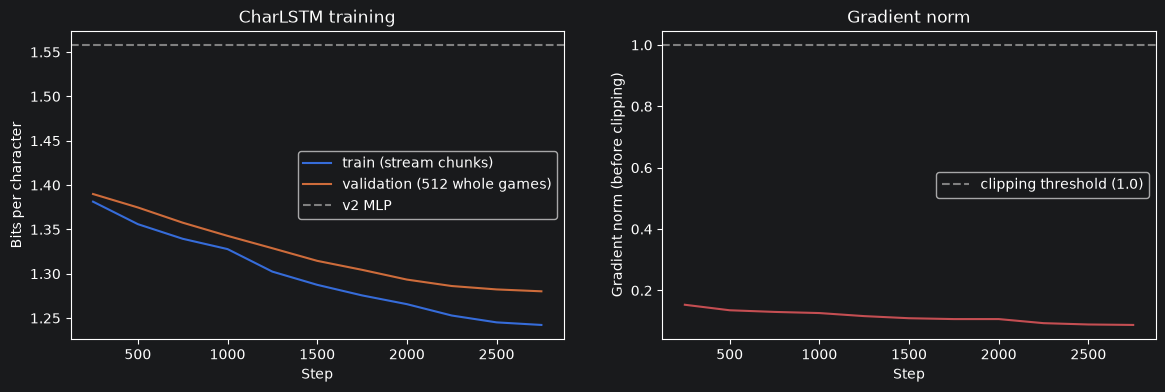

In [7]:
# --- TRAINING SETTINGS ---

# Complete passes over the training stream.
EPOCHS = 3

# Total optimisation steps: one per chunk.
STEPS = EPOCHS * chunks_per_epoch

# Initial learning rate.
LR = 2e-3

# Maximum gradient norm.
CLIP = 1.0

# Evaluate every EVAL_EVERY steps.
EVAL_EVERY = 250

# AdamW optimiser.
optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=0.01)

# Cosine decay over all steps, down to LR / 20.
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=STEPS, eta_min=LR / 20)


# Characters read at once during evaluation (the state carries the memory across pieces).
EVAL_PIECE = 128


# Exact loss on a set of whole validation games, plus the loss at every character position.
@torch.no_grad()
def eval_games(rows, batch=64):
    """Return (average NLL in nats, sum of NLL per position, count per position)."""

    # Evaluation mode.
    model.eval()

    # Sort the games by length, so that each batch contains games of similar length (little padding).
    rows = rows[torch.argsort(val_lengths_t[rows])]

    # Full width of the validation matrix: the per-position arrays must cover the longest game.
    max_len = val_matrix_t.shape[1]

    # Sum of the losses at each position (for the position diagnostic).
    pos_sum = torch.zeros(max_len - 1, device=device)

    # Number of real (non-padding) targets at each position.
    pos_count = torch.zeros(max_len - 1, device=device)

    # Go through the games in chunks.
    for i in range(0, len(rows), batch):

        # Inputs and targets of this group of games.
        x, y = make_batch(val_matrix_t, val_lengths_t, rows[i:i + batch])

        # Zero state at the start of every game.
        state = None

        # Logits of every piece.
        pieces = []

        # Read the games EVAL_PIECE characters at a time.
        for t0 in range(0, x.shape[1], EVAL_PIECE):

            # Logits of this piece, and the state to continue from.
            piece_logits, state = model(x[:, t0:t0 + EVAL_PIECE], state)

            # Keep the logits.
            pieces.append(piece_logits)

        # Logits at every position: pieces joined along the time axis.
        logits = torch.cat(pieces, dim=1)

        # Loss of every single target (reduction="none"); padding gives 0 thanks to ignore_index.
        losses = F.cross_entropy(logits.reshape(-1, V), y.reshape(-1), ignore_index=-100, reduction="none").view(y.shape)

        # Mask of the real targets.
        mask = (y != -100).float()

        # Width of this group.
        L = y.shape[1]

        # Accumulate per position (sum over the games of the group).
        pos_sum[:L] += (losses * mask).sum(dim=0)

        # Count the real targets per position.
        pos_count[:L] += mask.sum(dim=0)

    # Back to training mode.
    model.train()

    # Give the cached GPU memory of the evaluation back (only on Apple GPUs).
    if device.type == "mps":

        # Release unused cached blocks.
        torch.mps.empty_cache()

    # Average NLL over all real targets, and the per-position arrays on the CPU.
    return (pos_sum.sum() / pos_count.sum()).item(), pos_sum.cpu().numpy(), pos_count.cpu().numpy()


# 512 fixed validation games for the periodic evaluation (indices on the CPU, like the matrix).
val_sample_rows = torch.arange(512)

# History for the plots.
history = {"step": [], "train": [], "val": [], "grad_norm": []}

# Running sum of the training loss, kept on the GPU.
running_loss = torch.zeros((), device=device)

# Running sum of gradient norms.
running_norm = torch.zeros((), device=device)

# Global step counter.
step = 0

# Start time.
start = time.perf_counter()

# Training mode.
model.train()

# Passes over the training stream.
for epoch in range(EPOCHS):

    # The streams start again from their first character: zero state.
    state = None

    # Consecutive chunks of the streams.
    for k in range(chunks_per_epoch):

        # One more step.
        step += 1

        # Inputs and targets of chunk k, shape (N_STREAMS, BPTT).
        x, y = get_chunk(k)

        # Keep the values of the state but cut the gradient at the chunk boundary.
        if state is not None:

            # Detach h and c of every layer.
            state = [(h.detach(), c.detach()) for h, c in state]

        # Forward pass over the chunk, starting from the state left by the previous chunk.
        logits, state = model(x, state)

        # Cross-entropy over all targets (no padding in the stream).
        loss = F.cross_entropy(logits.reshape(-1, V), y.reshape(-1))

        # Reset gradients.
        optimizer.zero_grad()

        # Backpropagation through the BPTT steps of this chunk.
        loss.backward()

        # Clip the gradient norm to CLIP; returns the norm before clipping.
        norm = torch.nn.utils.clip_grad_norm_(model.parameters(), CLIP)

        # Update the weights.
        optimizer.step()

        # Update the learning rate.
        scheduler.step()

        # Accumulate the loss on the GPU.
        running_loss += loss.detach()

        # Accumulate the gradient norm.
        running_norm += norm.detach()

        # Early time check after 20 steps.
        if step == 20:

            # The GPU works asynchronously: wait until it has really finished the 20 steps before reading the clock.
            loss.item()

            # Seconds per step so far (the first steps include some warm-up, so this is slightly pessimistic).
            per_step = (time.perf_counter() - start) / step

            # Projected total training time.
            print(f"{per_step:.2f} s/step -> about {per_step * STEPS / 60:.0f} minutes for {STEPS:,} steps (plus evaluations)")

        # Periodic evaluation.
        if step % EVAL_EVERY == 0:

            # Average training loss since the last evaluation.
            train_loss = running_loss.item() / EVAL_EVERY

            # Average gradient norm since the last evaluation.
            grad_norm = running_norm.item() / EVAL_EVERY

            # Reset the running sums.
            running_loss.zero_()

            # Same for the norm.
            running_norm.zero_()

            # Validation loss on the 512 fixed whole games.
            val_loss, _, _ = eval_games(val_sample_rows)

            # Store the step.
            history["step"].append(step)

            # Training loss.
            history["train"].append(train_loss)

            # Validation loss.
            history["val"].append(val_loss)

            # Gradient norm.
            history["grad_norm"].append(grad_norm)

            # Progress line in bits per character.
            print(f"epoch {epoch + 1} | step {step:5d}/{STEPS} | train {train_loss / np.log(2):.3f} bpc | "
                  f"val {val_loss / np.log(2):.3f} bpc | grad norm {grad_norm:.2f} | {time.perf_counter() - start:.0f}s")

# --- EXACT VALIDATION LOSS ON ALL GAMES ---

# All validation games.
nll_lstm, pos_sum, pos_count = eval_games(torch.arange(len(val_lengths_t)))

# Bits per character.
bpc_lstm = nll_lstm / np.log(2)

# Report with the previous versions.
print(f"\nValidation: {bpc_lstm:.3f} bits/char | perplexity {np.exp(nll_lstm):.2f}   (v1 bigram 2.430, v2 MLP 1.558)")

# --- TRAINING CURVES ---

# Two panels.
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4))

# Training loss in bits per character.
ax1.plot(history["step"], np.array(history["train"]) / np.log(2), label="train (stream chunks)")

# Validation loss.
ax1.plot(history["step"], np.array(history["val"]) / np.log(2), label="validation (512 whole games)")

# v2 reference.
ax1.axhline(1.558, linestyle="--", color="gray", label="v2 MLP")

# x-axis label.
ax1.set_xlabel("Step")

# y-axis label.
ax1.set_ylabel("Bits per character")

# Title.
ax1.set_title("CharLSTM training")

# Legend.
ax1.legend()

# Average gradient norm before clipping.
ax2.plot(history["step"], history["grad_norm"], color="#C44E52")

# The clipping threshold.
ax2.axhline(CLIP, linestyle="--", color="gray", label=f"clipping threshold ({CLIP})")

# x-axis label.
ax2.set_xlabel("Step")

# y-axis label.
ax2.set_ylabel("Gradient norm (before clipping)")

# Title.
ax2.set_title("Gradient norm")

# Legend.
ax2.legend()

# Render.
plt.show()

## Step 5 — Does the memory hold up? Loss along the game

For each character position $t$ in the game, we average the loss over all validation games that are at least that long:

$$
\bar{\ell}(t) = \frac{\sum_{g} m_{g,t}\, \ell_{g,t}}{\sum_{g} m_{g,t}}
$$

The x-axis is converted to plies (about 4.14 characters per ply).

What to look for:
- the loss is **low at the start**: openings are well known;
- then it rises: the middle game is genuinely less predictable;
- if the memory **degraded** with length, the loss would keep growing late in the game. A flat or decreasing curve means the LSTM keeps track of long games.

The dashed line marks the **gradient horizon** of truncated BPTT: 64 characters, about 15 plies. The gradient never connected a prediction to anything more than 64 characters earlier, yet the state carries information much further. If the curve stays flat far beyond the line, the LSTM learned to keep useful information longer than it was ever explicitly trained to. Only bins with at least 100 games are shown, since very long games are rare and their average is noisy.

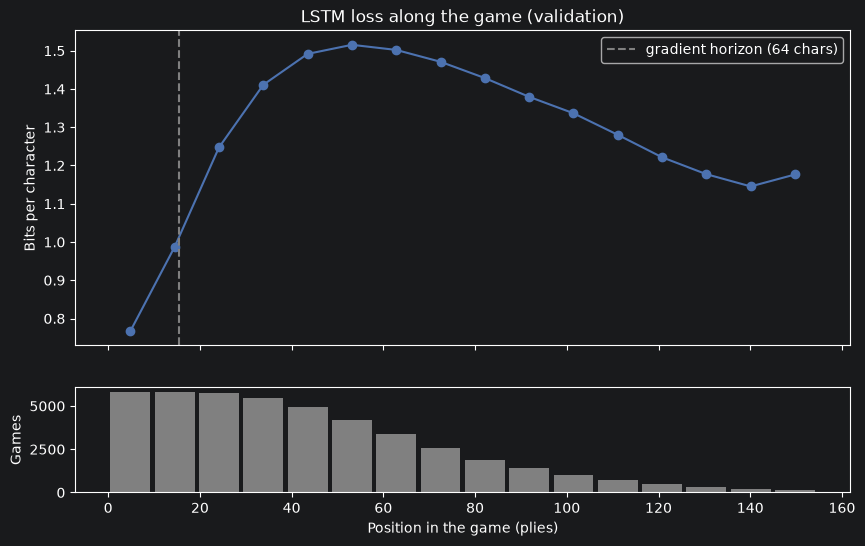

In [8]:
# --- LOSS AS A FUNCTION OF THE POSITION IN THE GAME ---

# Width of each bin, in characters.
BIN = 40

# Number of complete bins.
n_bins = len(pos_sum) // BIN

# Sum of the losses in each bin (reshape groups BIN consecutive positions).
bin_sum = pos_sum[:n_bins * BIN].reshape(n_bins, BIN).sum(axis=1)

# Number of targets in each bin.
bin_count = pos_count[:n_bins * BIN].reshape(n_bins, BIN).sum(axis=1)

# Number of games still running at the start of each bin.
games_alive = pos_count[::BIN][:n_bins]

# Keep only bins with at least 100 games.
keep = games_alive >= 100

# Centre of each bin, converted from characters to plies.
centres_plies = (np.arange(n_bins) * BIN + BIN / 2) / 4.14

# Two panels sharing the x-axis.
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6), sharex=True, gridspec_kw={"height_ratios": [3, 1]})

# Average bits per character in each bin.
ax1.plot(centres_plies[keep], (bin_sum[keep] / bin_count[keep]) / np.log(2), marker="o", color="#4C72B0")

# Gradient horizon of truncated BPTT (64 characters), in plies.
ax1.axvline(BPTT / 4.14, linestyle="--", color="gray", label=f"gradient horizon ({BPTT} chars)")

# y-axis label.
ax1.set_ylabel("Bits per character")

# Title.
ax1.set_title("LSTM loss along the game (validation)")

# Legend.
ax1.legend()

# Bottom panel: how many games reach each point.
ax2.bar(centres_plies[keep], games_alive[keep], width=BIN / 4.14 * 0.9, color="gray")

# x-axis label.
ax2.set_xlabel("Position in the game (plies)")

# y-axis label.
ax2.set_ylabel("Games")

# Render.
plt.show()

## Step 6 — Incremental sampling and the evaluation harness

### Carrying the hidden state forward
The common interface is still `next_char_probs(context)`. Re-reading the whole game for every new character would cost $O(T)$ per character, so $O(T^2)$ per game: very slow for long games.

An RNN does not need that: its hidden state $(h_t, c_t)$ already **summarises everything read so far**. The `LSTMSampler` remembers the last context and state:
- if the new context **extends** the previous one, it feeds only the new characters, one LSTM step each;
- otherwise (a new test position), it starts again from scratch.

$$
(h_{t+1}, c_{t+1}) = \text{LSTM}\big(x_{t+1}, (h_t, c_t)\big)
$$

This is exactly why recurrent networks were attractive for generation, and the GPT of v4 will need its own trick (the KV cache) to achieve the same.

### The rest of the harness
Identical to v2: the same 1,000 test positions (seed 123), legality, well-formedness, self-play, and phase bins. The bigram is rebuilt for comparison. For the v2 MLP we use its saved results; its per-phase rates were not saved, so they are read off the v2 chart (approximate).
From v3 onwards the per-phase rates are saved too.

In [9]:
# --- INCREMENTAL LSTM SAMPLER (on the CPU) ---

# Copy of the trained model on the CPU, in evaluation mode.
model_cpu = copy.deepcopy(model).to("cpu").eval()


# Next-character distribution with a cached hidden state.
class LSTMSampler:
    """Callable object: context (list of indices) -> probabilities of the next character."""

    # Start with an empty cache.
    def __init__(self, model):

        # The (CPU) model.
        self.model = model

        # Context already read.
        self.context = []

        # LSTM state (h, c) after reading self.context; None means "zero state".
        self.state = None

        # Logits produced after the last character read.
        self.logits = None

    # Make the object callable like a function.
    @torch.no_grad()
    def __call__(self, context):

        # Length of the cached context.
        n = len(self.context)

        # If the new context does not start with the cached one, start again from scratch.
        if n == 0 or len(context) < n or context[:n] != self.context:

            # Reset the cache.
            self.context, self.state, n = [], None, 0

        # Characters not read yet.
        new = context[n:]

        # Feed them, if any.
        if new:

            # One batch with one sequence of the new characters.
            logits, self.state = self.model(torch.tensor([new]), self.state)

            # Keep the logits after the last of them.
            self.logits = logits[0, -1]

            # Remember the full context.
            self.context = list(context)

        # Softmax as float64 NumPy, for precise sampling.
        return F.softmax(self.logits, dim=0).numpy().astype(np.float64)


# The sampler used for evaluation.
lstm_next_char_probs = LSTMSampler(model_cpu)

# --- REBUILD THE v1 BIGRAM ---

# Training text as in v1.
bigram_ids = encode(SEP + SEP.join(train_games) + SEP)

# Pair counts.
counts = np.bincount(bigram_ids[:-1] * V + bigram_ids[1:], minlength=V * V).reshape(V, V)

# Smoothed probabilities.
P_count = (counts + 1.0) / (counts + 1.0).sum(axis=1, keepdims=True)


# Bigram next-character distribution.
def bigram_next_char_probs(context):
    """Row of the bigram table for the last character."""

    # Probability vector.
    return P_count[context[-1]]


# --- SAMPLING HELPERS ---

# Sample an index with temperature.
def sample_from(probs, temperature=1.0):
    """p^(1/T), renormalised, one draw."""

    # Sharpen or flatten.
    p = probs ** (1.0 / temperature)

    # Renormalise.
    p = p / p.sum()

    # Draw.
    return np.random.choice(len(p), p=p)


# Sample one move.
def sample_move(next_char_probs, context, temperature=1.0, max_len=10):
    """Return (move string, ended)."""

    # Copy of the context.
    context = list(context)

    # Characters of the move.
    move_chars = []

    # At most max_len characters.
    for _ in range(max_len):

        # Next character.
        nxt = sample_from(next_char_probs(context), temperature)

        # Space: end of move.
        if nxt == stoi[" "]:

            # Stop.
            break

        # Separator: end of game.
        if nxt == stoi[SEP]:

            # Signal the end.
            return "".join(move_chars), True

        # Part of the move.
        move_chars.append(itos[nxt])

        # Becomes context.
        context.append(nxt)

    # The move.
    return "".join(move_chars), False


# Context for a game prefix.
def prefix_context(moves):
    """';' + moves + trailing space."""

    # Text.
    text = SEP + " ".join(moves) + (" " if moves else "")

    # Encoded.
    return [stoi[c] for c in text]


# --- LEGALITY AND WELL-FORMEDNESS ---

# Legal move check.
def is_legal(board, san):
    """True for a legal move (False for illegal, malformed or null moves)."""

    # Try to parse.
    try:

        # Null move "--" is falsy.
        return bool(board.parse_san(san))

    # Parsing error.
    except ValueError:

        # Illegal.
        return False


# SAN grammar.
SAN_RE = re.compile(r"^(O-O(-O)?|[KQRBN][a-h]?[1-8]?x?[a-h][1-8]|[a-h](x[a-h])?[1-8](=[QRBN])?)[+#]?$")


# Well-formed check.
def is_well_formed(san):
    """True if the string matches the SAN grammar."""

    # Regex match.
    return SAN_RE.match(san) is not None


# --- THE SAME 1,000 TEST POSITIONS ---

# Same seed as v1 and v2.
pos_rng = random.Random(123)

# (moves, board) pairs.
test_positions = []

# Draw 1,000 positions.
while len(test_positions) < 1000:

    # Random test game.
    moves = pos_rng.choice(test_games).split()

    # Random cut point.
    k = pos_rng.randrange(len(moves))

    # Replay the prefix.
    board = chess.Board()

    # Each move.
    for m in moves[:k]:

        # Play it.
        board.push_san(m)

    # Store.
    test_positions.append((moves[:k], board))


# Evaluate a move proposer.
def evaluate_legality(propose_move):
    """Return (legal rate, well-formed rate, list of (k, legal, san))."""

    # Details.
    results = []

    # Each position.
    for moves, board in test_positions:

        # Proposed move.
        san = propose_move(moves)

        # Store.
        results.append((len(moves), is_legal(board, san), san))

    # Legal rate.
    legal_rate = np.mean([legal for _, legal, _ in results])

    # Well-formed rate.
    well_formed_rate = np.mean([is_well_formed(san) for _, _, san in results])

    # Return.
    return legal_rate, well_formed_rate, results


# Character model -> move proposer.
def char_model_proposer(next_char_probs, temperature=1.0):
    """moves -> sampled SAN."""

    # The proposer.
    def propose(moves):

        # Sample.
        san, _ = sample_move(next_char_probs, prefix_context(moves), temperature)

        # Return.
        return san

    # Return the function.
    return propose


# --- FREQUENCY BASELINE ---

# Training move counts.
train_move_counts = Counter(m for g in train_games for m in g.split())

# Distinct moves.
baseline_moves = list(train_move_counts.keys())

# Weights.
baseline_weights = list(train_move_counts.values())


# Random move with training frequencies.
def frequency_baseline(moves):
    """Weighted random move, ignoring the position."""

    # Draw.
    return random.choices(baseline_moves, weights=baseline_weights, k=1)[0]


# --- SELF-PLAY ---

# Both sides played by the model.
def self_play(next_char_probs, n_games=200, max_plies=300, temperature=1.0):
    """Return (legal plies per game, sequences)."""

    # Results.
    legal_plies, sequences = [], []

    # Each game.
    for _ in range(n_games):

        # New board.
        board = chess.Board()

        # Moves.
        moves = []

        # Play.
        while len(moves) < max_plies and not board.is_game_over():

            # Next move.
            san, ended = sample_move(next_char_probs, prefix_context(moves), temperature)

            # Stop on end token or illegal move.
            if ended or not is_legal(board, san):

                # Leave.
                break

            # Play.
            board.push_san(san)

            # Remember.
            moves.append(san)

        # Store plies.
        legal_plies.append(len(moves))

        # Store sequence.
        sequences.append(moves)

    # Return.
    return legal_plies, sequences


# Phase bins.
PHASE_BINS = [(0, 10), (10, 20), (20, 40), (40, 80), (80, 10_000)]

# Labels.
PHASE_LABELS = ["0-9", "10-19", "20-39", "40-79", "80+"]


# Legal rate by phase.
def rate_by_phase(results):
    """One legal rate per phase bin."""

    # Values.
    rates = []

    # Each bin.
    for lo, hi in PHASE_BINS:

        # Legality in the bin.
        in_bin = [legal for k, legal, _ in results if lo <= k < hi]

        # Mean or NaN.
        rates.append(np.mean(in_bin) if in_bin else np.nan)

    # Return.
    return rates


# --- RESULTS OF THE PREVIOUS VERSIONS ---

# Shared results file.
RESULTS_PATH = DATA_DIR / "chessgpt_results.json"

# Load it.
results_all = json.loads(RESULTS_PATH.read_text())

# Legal rate of the v2 MLP.
legal_mlp = results_all["v2_mlp"]["legal_rate"]

# Self-play of the v2 MLP.
selfplay_mlp = results_all["v2_mlp"]["selfplay_mean_plies"]

# Per-phase legal rates of the v2 MLP, read off the v2 chart (approximate: they were not saved).
V2_PHASE = [0.78, 0.42, 0.26, 0.21, 0.24]

## Step 7 — Results: does the memory make moves legal?

**Expected:** the LSTM should match the MLP in the opening and beat it clearly in the middle game, where remembering moves played long ago matters most.

Evaluation time: 12s

model                  well-formed   legal
frequency baseline          100.0%   11.2%
v1 bigram                    94.1%   10.2%
v2 MLP (saved)              100.0%   36.9%
v3 LSTM                     100.0%   55.4%

Self-play (200 games, 2s): LSTM mean 10.43 legal plies (median 10, max 21)   (v2 MLP: 6.58)


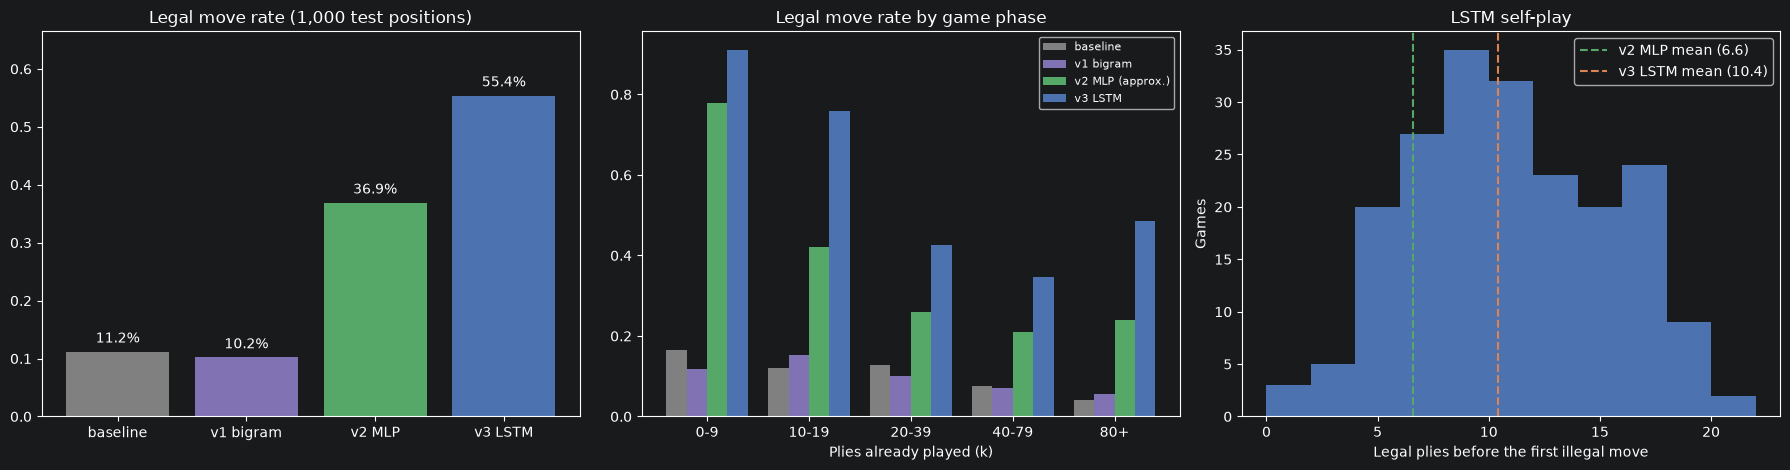

In [10]:
# --- NEXT-MOVE LEGALITY ON THE 1,000 TEST POSITIONS ---

# Fixed seeds.
np.random.seed(0)

# Same for Python's random module.
random.seed(0)

# Start time.
start = time.perf_counter()

# Baseline.
legal_base, wf_base, res_base = evaluate_legality(frequency_baseline)

# Bigram.
legal_bigram, wf_bigram, res_bigram = evaluate_legality(char_model_proposer(bigram_next_char_probs))

# LSTM.
legal_lstm, wf_lstm, res_lstm = evaluate_legality(char_model_proposer(lstm_next_char_probs))

# Evaluation time.
print(f"Evaluation time: {time.perf_counter() - start:.0f}s\n")

# Header.
print(f"{'model':<22}{'well-formed':>12}{'legal':>8}")

# Baseline.
print(f"{'frequency baseline':<22}{wf_base:>12.1%}{legal_base:>8.1%}")

# Bigram.
print(f"{'v1 bigram':<22}{wf_bigram:>12.1%}{legal_bigram:>8.1%}")

# MLP (saved results).
print(f"{'v2 MLP (saved)':<22}{results_all['v2_mlp']['well_formed_rate']:>12.1%}{legal_mlp:>8.1%}")

# LSTM.
print(f"{'v3 LSTM':<22}{wf_lstm:>12.1%}{legal_lstm:>8.1%}")

# --- SELF-PLAY ---

# Start time.
start = time.perf_counter()

# LSTM self-play.
lstm_plies, lstm_sequences = self_play(lstm_next_char_probs)

# Report.
print(f"\nSelf-play (200 games, {time.perf_counter() - start:.0f}s): LSTM mean {np.mean(lstm_plies):.2f} legal plies "
      f"(median {np.median(lstm_plies):.0f}, max {max(lstm_plies)})   (v2 MLP: {selfplay_mlp:.2f})")

# Phase rates of the LSTM.
phase_lstm = rate_by_phase(res_lstm)

# --- PLOTS ---

# Three panels.
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 4.8))

# Model names.
names = ["baseline", "v1 bigram", "v2 MLP", "v3 LSTM"]

# Legal rates.
legal_rates = [legal_base, legal_bigram, legal_mlp, legal_lstm]

# One bar per model.
bars = ax1.bar(names, legal_rates, color=["gray", "#8172B3", "#55A868", "#4C72B0"])

# Value labels.
for bar, value in zip(bars, legal_rates):

    # Label above the bar.
    ax1.text(bar.get_x() + bar.get_width() / 2, value + 0.01, f"{value:.1%}", ha="center", va="bottom")

# Room above the bars.
ax1.set_ylim(0, max(legal_rates) * 1.2)

# Title.
ax1.set_title("Legal move rate (1,000 test positions)")

# Phase chart.
xp = np.arange(len(PHASE_LABELS))

# Baseline.
ax2.bar(xp - 0.3, rate_by_phase(res_base), width=0.2, color="gray", label="baseline")

# Bigram.
ax2.bar(xp - 0.1, rate_by_phase(res_bigram), width=0.2, color="#8172B3", label="v1 bigram")

# MLP (approximate values from v2).
ax2.bar(xp + 0.1, V2_PHASE, width=0.2, color="#55A868", label="v2 MLP (approx.)")

# LSTM.
ax2.bar(xp + 0.3, phase_lstm, width=0.2, color="#4C72B0", label="v3 LSTM")

# Bin labels.
ax2.set_xticks(xp, PHASE_LABELS)

# x-axis label.
ax2.set_xlabel("Plies already played (k)")

# Title.
ax2.set_title("Legal move rate by game phase")

# Legend.
ax2.legend(fontsize=8)

# Self-play histogram, bins of 2 plies.
ax3.hist(lstm_plies, bins=range(0, max(lstm_plies) + 3, 2), color="#4C72B0")

# v2 reference.
ax3.axvline(selfplay_mlp, linestyle="--", color="#55A868", label=f"v2 MLP mean ({selfplay_mlp:.1f})")

# LSTM mean.
ax3.axvline(np.mean(lstm_plies), linestyle="--", color="#DD8452", label=f"v3 LSTM mean ({np.mean(lstm_plies):.1f})")

# Labels.
ax3.set_xlabel("Legal plies before the first illegal move")

# y-axis label.
ax3.set_ylabel("Games")

# Title.
ax3.set_title("LSTM self-play")

# Legend.
ax3.legend()

# Layout.
plt.tight_layout()

# Render.
plt.show()

## Step 8 — Temperature, examples and the longest game

Same analyses as v2: legality at lower temperatures, a few commented examples, and the board at the end of the longest legal self-play game.

 temperature  well-formed   legal
         1.0       100.0%   57.4%
         0.8       100.0%   60.5%
         0.5       100.0%   63.2%

Examples (last moves of the context -> LSTM move):
  ply  34 | ...Bd4 Qe7 Qa5 b6               -> Nd2      well-formed but illegal
  ply  49 | ...Qg6 Qxd7+ Qf7 Re7            -> Rf7      well-formed but illegal
  ply  17 | ...d6 Nf3 d5 cxd5               -> Nxd5     legal
  ply   9 | ...Bc5 Nf3 d6 d4                -> Bh4+     well-formed but illegal
  ply  34 | ...Ng5 Bc5+ Bf2 Qg3+            -> Kh1      legal
  ply  42 | ...gxf4 gxf4 Kf3 fxe3           -> Kxe3     well-formed but illegal
  ply   1 | ...g3                           -> b6       legal
  ply   8 | ...e4 Bb4 a3 Bc5                -> b4       legal
  ply  42 | ...Qf4 Bc6 Nh4 Nh5              -> Qg4      legal
  ply  31 | ...Ng4 Rh1 Kh8 Bd2              -> Nh5      well-formed but illegal

Longest legal LSTM self-play game (21 plies): f4 b6 Nf3 Bb7 Nc3 Bxf3 exf3 d5 d4 c6 Bd2 e6 a3 b5 Ne2 B

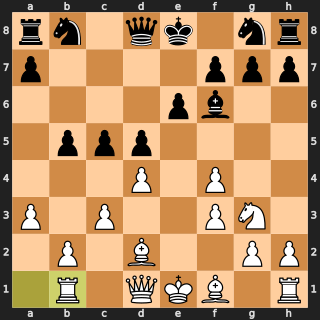

In [11]:
# --- TEMPERATURE SWEEP ---

# Header.
print(f"{'temperature':>12}{'well-formed':>13}{'legal':>8}")

# Three temperatures.
for T in [1.0, 0.8, 0.5]:

    # Same seed for each temperature.
    np.random.seed(0)

    # Evaluate.
    legal_T, wf_T, _ = evaluate_legality(char_model_proposer(lstm_next_char_probs, temperature=T))

    # Row.
    print(f"{T:>12.1f}{wf_T:>13.1%}{legal_T:>8.1%}")

# --- EXAMPLES ---

# Title.
print("\nExamples (last moves of the context -> LSTM move):")

# First 10 test positions.
for (moves, board), (k, legal, san) in zip(test_positions[:10], res_lstm[:10]):

    # Verdict.
    verdict = "legal" if legal else ("well-formed but illegal" if is_well_formed(san) else "malformed")

    # Last 4 moves of the context.
    tail = " ".join(moves[-4:]) if moves else "(start)"

    # Print.
    print(f"  ply {k:3d} | ...{tail:<28} -> {san:<8} {verdict}")

# --- LONGEST LEGAL SELF-PLAY GAME ---

# Index of the longest game.
best = int(np.argmax(lstm_plies))

# Its moves.
best_moves = lstm_sequences[best]

# Print them.
print(f"\nLongest legal LSTM self-play game ({len(best_moves)} plies):", " ".join(best_moves))

# Replay it.
board = chess.Board()

# Each move.
for m in best_moves:

    # Play.
    board.push_san(m)

# Draw the final position.
display(SVG(chess.svg.board(board, lastmove=board.peek() if best_moves else None, size=320)))

## Step 9 — Save the results

The v3 results are added to the shared file, **including the per-phase legal rates** (from now on every version saves them), so that v6 can draw the full comparison.

In [12]:
# --- SAVE THE RESULTS OF v3 ---

# Results of the LSTM.
results_all["v3_lstm"] = {
    # Validation bits per character.
    "val_bpc": float(bpc_lstm),
    # Legal move rate at temperature 1.
    "legal_rate": float(legal_lstm),
    # Well-formed rate.
    "well_formed_rate": float(wf_lstm),
    # Mean legal plies in self-play.
    "selfplay_mean_plies": float(np.mean(lstm_plies)),
    # Legal rate in each phase bin.
    "phase_legal_rates": [float(r) for r in phase_lstm],
    # Number of parameters.
    "params": int(n_params),
}

# Write the file.
RESULTS_PATH.write_text(json.dumps(results_all, indent=2))

# Show it.
print(json.dumps(results_all, indent=2))

{
  "baseline": {
    "legal_rate": 0.112,
    "well_formed_rate": 1.0
  },
  "v1_bigram": {
    "val_bpc": 2.4304427985659216,
    "legal_rate": 0.102,
    "selfplay_mean_plies": 0.305,
    "well_formed_rate": 0.941
  },
  "v2_mlp": {
    "val_bpc": 1.5581939788328818,
    "legal_rate": 0.369,
    "well_formed_rate": 1.0,
    "selfplay_mean_plies": 6.58,
    "params": 475349
  },
  "v3_lstm": {
    "val_bpc": 1.2579778486516928,
    "legal_rate": 0.554,
    "well_formed_rate": 1.0,
    "selfplay_mean_plies": 10.425,
    "phase_legal_rates": [
      0.9112426035502958,
      0.7591623036649214,
      0.4270833333333333,
      0.3464285714285714,
      0.4861111111111111
    ],
    "params": 1883869
  }
}


## Results and conclusions

### Summary
| Model | Parameters | Context | Val bits/char | Legal move rate | Self-play plies |
|---|---|---|---|---|---|
| Frequency baseline | — | none | — | 11.2% | — |
| v1 Bigram | 841 | 1 character | 2.430 | 10.2% | 0.31 |
| v2 MLP + embeddings | 475,349 | 16 characters | 1.558 | 36.9% | 6.58 |
| **v3 LSTM** | **1,883,869** | **the whole game** | **1.258** | **55.4%** | **10.43** |

The LSTM lowers the validation loss by 0.30 bits per character compared with the MLP (perplexity 2.39: on average the model hesitates between about 2.4 characters). It raises the legal move rate from 36.9% to **55.4%**: for the first time, more than half of the proposed moves are legal.

### Training
- **Note on this run:** the training cell was executed twice in a row without re-creating the model. The final model therefore had 2 × 3 epochs (about 5,500 steps), and the learning rate restarted from $2 \cdot 10^{-3}$ at the beginning of the second run (a "warm restart"). The curves show the second run only, which starts at about 1.39 bits per character.
- Train and validation stay close (gap about 0.04 bits per character): **no overfitting**. Both are still decreasing slowly, so longer training or a bigger model would still help.
- The gradient norm stays between 0.09 and 0.15, far below the clipping threshold of 1.0. With truncated BPTT over 64 steps the gradients are well behaved: clipping is only a safety net here.

### Legal move rate by game phase
| Plies already played | v2 MLP (approx.) | v3 LSTM | Gain |
|---|---|---|---|
| 0–9 | 78% | **91%** | +13 |
| 10–19 | 42% | **76%** | +34 |
| 20–39 | 26% | **43%** | +17 |
| 40–79 | 21% | **35%** | +14 |
| 80+ | 24% | **49%** | +25 |

- The biggest gain is at plies **10–19**, exactly where the moves that placed the pieces fall outside the MLP's 16-character window (about 4 plies). The LSTM still remembers them.
- The gain persists in the middle game and in long games: the memory is useful along the whole game, not only in the opening.
- The rate rises again after ply 80: endgames have few pieces left, so there are fewer ways to make a mistake. That bin also contains fewer positions, so it is noisier.
- In the middle game, however, more than half of the moves are **still illegal**.

### Loss along the game
- The loss is about 0.77 bits per character in the first 10 plies (well-known openings), peaks at about **1.52 around ply 50** (the middle game, the least predictable part), then decreases to about 1.15 around ply 140.
- There is **no degradation in long games**: the state keeps working far beyond the 64-character gradient horizon (about 15 plies). The LSTM learned to keep information much longer than it was ever explicitly trained to.
- Caveat: the decrease late in the game is partly a matter of **composition**. Very long games are endgames with few pieces, where moves are more predictable (king moves, pawn pushes). The curve shows that the memory does not collapse, but it does not prove that the board is tracked perfectly.

### Temperature
| Temperature | Legal |
|---|---|
| 1.0 | 57.4% |
| 0.8 | 60.5% |
| 0.5 | **63.2%** |

- At $T = 1$ this sweep measures 57.4%, against 55.4% in Step 7. The difference is **sampling noise**: with 1,000 positions the standard error is $\sqrt{0.55 \cdot 0.45 / 1000} \approx 1.6$ percentage points.
- Lower temperatures help, as in v2: many illegal moves come from the low-probability tail of the distribution.

### What the mistakes look like
Typical errors, such as `Nd2`, `Rf7` or `Kxe3`, are **plausible** moves: the right kind of piece, a reasonable square, correct notation (100% well-formed). But the piece cannot reach that square, or the square is occupied. The model knows the *style* of chess moves very well, but its picture of the board is blurred.

### Self-play
- Mean **10.4 legal plies** before the first illegal move (median 10, max 21), against 6.6 for the MLP.
- Longest game: `1.f4 b6 2.Nf3 Bb7 3.Nc3 Bxf3 4.exf3 d5 5.d4 c6 6.Bd2 e6 7.a3 b5 8.Ne2 Be7 9.Ng3 Bf6 10.c3 c5 11.Rb1`: a coherent Bird's Opening, with Black's queenside fianchetto and a capture on f3.

### Limits and next step
- A single state vector of 384 numbers must encode the whole position (64 squares, castling rights, whose turn it is), updated one character at a time. Precise information, such as "the knight on f3 has already moved to d4", gets blurred over many steps.
- The computation is **sequential**: step $t$ must wait for step $t - 1$, so training cannot be parallelised along the game.
- **v4, a GPT from scratch:** with **self-attention**, every new character can look *directly* at any earlier character (for example, at the move that brought the knight to f3), instead of hoping that the information survived inside the state. And all positions of a sequence are trained **in parallel**.